# Phase 4.4 — Strategy Robustness & Research Protocol

This notebook visualizes **development-only (2019–2021)** threshold selection, market regimes, transaction-cost sensitivity and paired moving-block bootstrap. Run `python -m quant_trading.phase4_robustness` after Phase 4 backtesting. All statistical intervals are **exploratory and conditional on previous model/threshold searches**.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

current_dir = Path.cwd().resolve()
for ROOT in (current_dir, *current_dir.parents):
    if (ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")
REPORT = ROOT / 'reports' / 'phase4_4'
config_file = REPORT / 'strategy_config.json'
assert config_file.is_file(), 'Run python -m quant_trading.phase4_robustness first'
config = json.loads(config_file.read_text(encoding='utf-8'))
print('Example model:', config['model_name'])
print('Selected development threshold:', config['selected_threshold'])
print('Eligibility met:', config['eligibility_met'])
print(config['selection_warning'])

Example model: XGBoost
Selected development threshold: 0.5
Eligibility met: True
Optimized on 2019–2021; reported development Sharpe is selection-biased. NOT independent evidence.


## Threshold sweep

The small grid is **fixed in advance**. Selection uses development net Sharpe with a 10–95% exposure constraint. If none qualify, the fixed 0.50 fallback is **flagged**, and must not be represented as a successful Sharpe-optimized strategy.

,threshold,sharpe_ratio,cagr,market_exposure,one_sided_trades
0,0.50,0.964658,0.168167,0.847682,101
1,0.55,0.215603,0.020536,0.410596,271
2,0.60,-0.011270,-0.003713,0.041060,46


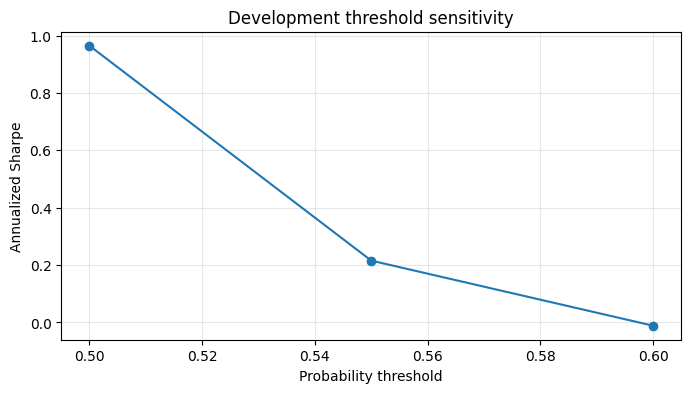

In [2]:
thresholds = pd.read_csv(REPORT / 'threshold_sweep.csv')
display(thresholds[['threshold','sharpe_ratio','cagr','market_exposure','one_sided_trades']])
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(thresholds.threshold, thresholds.sharpe_ratio, marker='o', label='Net Sharpe')
ax1.set(xlabel='Probability threshold', ylabel='Annualized Sharpe', title='Development threshold sensitivity')
ax1.grid(alpha=.3)
plt.show()

## Regime analysis

Regimes use a 75th-percentile volatility cutoff **fit on training data only**. Full-series positions and costs are computed *before* filtering into high/normal-volatility sessions. Do not interpret conditional scattered-period returns as an investable continuously-compounded sub-strategy.

,regime,observations,mean_strategy_return,mean_benchmark_return,mean_excess_return,market_exposure,one_sided_trades
0,High volatility,217,0.000575,0.001534,-0.000959,0.691244,45
1,Normal/low volatility,538,0.000722,0.000791,-0.000069,0.910781,56


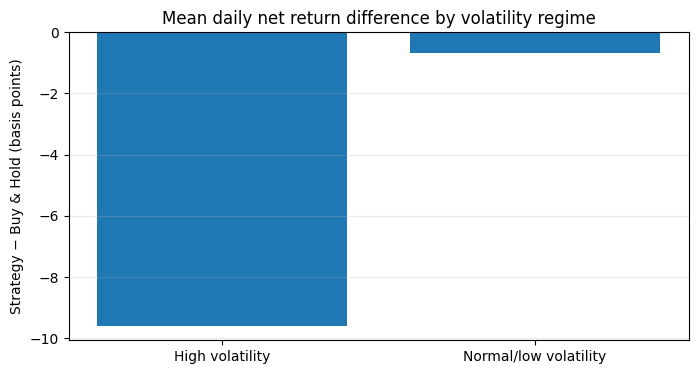

In [3]:
regimes = pd.read_csv(REPORT / 'regime_metrics.csv')
display(regimes)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(regimes.regime, regimes.mean_excess_return * 10000)
ax.set(title='Mean daily net return difference by volatility regime', ylabel='Strategy − Buy & Hold (basis points)')
ax.grid(alpha=.25, axis='y')
plt.show()

## Transaction cost scenarios

0, 5 and 10 bps per *one-sided* trade are **hypothetical assumptions**. The rule and probabilities are held fixed across scenarios.

,cost_bps,cagr,sharpe_ratio,max_drawdown,one_sided_trades
0,0.0,0.188053,1.059817,0.32049,101
1,5.0,0.168167,0.964658,0.32049,101
2,10.0,0.148605,0.869326,0.32049,101


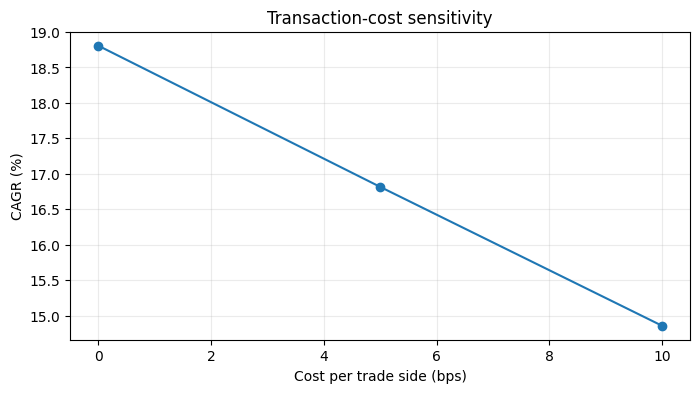

In [4]:
costs = pd.read_csv(REPORT / 'cost_sensitivity.csv')
display(costs[['cost_bps','cagr','sharpe_ratio','max_drawdown','one_sided_trades']])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(costs.cost_bps, costs.cagr * 100, marker='o')
ax.set(title='Transaction-cost sensitivity', xlabel='Cost per trade side (bps)', ylabel='CAGR (%)')
ax.grid(alpha=.25)
plt.show()

## Paired moving-block bootstrap

Per-period paired difference: `strategy net return − Buy & Hold net return`. Resample contiguous blocks for a **descriptive CI of the mean daily difference**, not Sharpe or CAGR. A CI excluding zero does **not** adjust for model selection or nonstationarity.

,block_length,observations,mean_daily_excess_return,ci_lower,ci_upper
0,5,755,-0.000325,-0.000707,0.000002
1,10,755,-0.000325,-0.000772,0.000027
2,20,755,-0.000325,-0.000799,0.000017


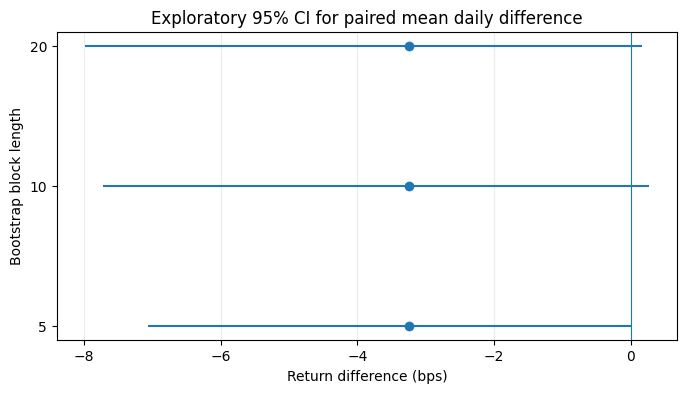

In [5]:
boot = pd.read_csv(REPORT / 'block_bootstrap.csv')
display(boot)
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(boot))
ax.errorbar(boot.mean_daily_excess_return * 1e4, y,
            xerr=[(boot.mean_daily_excess_return-boot.ci_lower)*1e4,
                  (boot.ci_upper-boot.mean_daily_excess_return)*1e4], fmt='o')
ax.axvline(0, linewidth=.8)
ax.set_yticks(y, labels=boot.block_length.astype(str))
ax.set(title='Exploratory 95% CI for paired mean daily difference', xlabel='Return difference (bps)', ylabel='Bootstrap block length')
ax.grid(alpha=.25, axis='x')
plt.show()

## Freeze before final held-out test

The Phase 4 package **never opens** `spy_test.parquet`. Before any 2022–2026 evaluation, freeze model family, all hyperparameters and scalers, refit decision and protocol, random seed protocol, threshold, transaction costs and benchmarks. If you then optimize on 2022–2026, it ceases to be an independent test.

**Execution caveat:** adjusted-open returns are historical proxies; deployment claims need a point-in-time opening-price and dividend accounting system.

## How robust is the selected XGBoost strategy?

At 5 basis points per side, development Sharpe is 0.965 at threshold 0.50, 0.216 at 0.55 and −0.011 at 0.60. The 0.60 rule has only 4.11% exposure and fails the predeclared minimum. The selected 0.50 rule has 84.77% exposure and gains 59.22% cumulatively. Buy & Hold gains 101.44% on the same dates. Both have a 32.05% maximum drawdown.

With the threshold fixed at 0.50, cumulative return declines from 67.47% at zero fees to 59.22% at 5 basis points and 51.38% at 10. Even before fees, the strategy trails the benchmark on these dates. Its mean daily net difference versus Buy & Hold is −9.59 basis points in high volatility and −0.69 in normal/low volatility. Over all sessions the mean is −3.25 basis points. The 10-session-block interval is [−7.72, +0.27] basis points per day. The 5- and 20-session intervals also include zero.

The sample shows underperformance. Its magnitude in a different period remains uncertain. Choosing 0.50 on this same window makes the reported Sharpe exploratory. The final holdout has not been evaluated.